## Channel flow with RANS
Philipp Schlatter, LSTM-FAU

Mixing length model

In [44]:
import numpy as np
import matplotlib.pyplot as plt

In [80]:
Retau=1000
kappa=0.41
Aplus=26
lmax=0.09

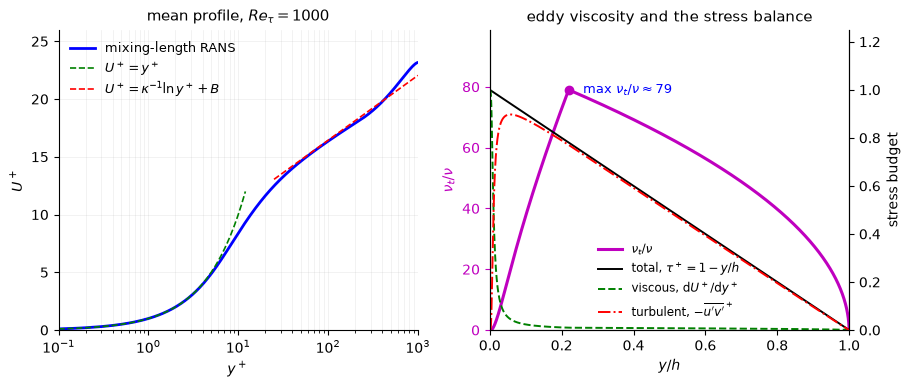

In [81]:
yp = np.linspace(0.0, Retau, 20001)
tau = 1.0 - yp / Retau                    # total stress, channel
lp = kappa * yp * (1.0 - np.exp(-yp / Aplus))   # van Driest mixing length
lp = np.minimum(lp, lmax * Retau)         # Escudier outer-layer limit
# (1 + nu_t+) dU+/dy+ = tau,  nu_t+ = l+^2 |dU+/dy+|
dUdy = 2.0 * tau / (1.0 + np.sqrt(1.0 + 4.0 * lp ** 2 * tau))
nut = lp ** 2 * dUdy
Up = np.concatenate(([0.0], np.cumsum(0.5 * (dUdy[1:] + dUdy[:-1])* np.diff(yp))))

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.9))

ax = axes[0]
ax.semilogx(np.maximum(yp, 1e-2), Up, color='b', lw=2.0,
                label="mixing-length RANS")
yv = np.logspace(-1, np.log10(12), 50)
ax.semilogx(yv, yv, color='g', lw=1.2, ls="--",
                label=r"$U^+=y^+$")
yl = np.logspace(np.log10(25), np.log10(Retau), 50)
ax.semilogx(yl, np.log(yl) / kappa + 5.2, color='r', lw=1.2, ls="--",
                label=r"$U^+=\kappa^{-1}\ln y^+ + B$")
ax.set_xlabel(r"$y^+$")
ax.set_ylabel(r"$U^+$")
ax.set_xlim(0.1, Retau)
ax.set_ylim(0, 26)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.grid(alpha=0.22, lw=0.5, which="both")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(rf"mean profile, $\mathit{{Re}}_\tau={Retau:.0f}$",
                 fontsize=10.5)

ax = axes[1]
ax.plot(yp / Retau, nut, color='m', lw=2.2, label=r"$\nu_t/\nu$")
jmax = np.argmax(nut)
ax.plot(yp[jmax] / Retau, nut[jmax], "o", ms=6, color='m')
ax.text(yp[jmax] / Retau + 0.04, nut[jmax],
            rf"$\max\,\nu_t/\nu\approx{nut[jmax]:.0f}$",
            fontsize=9.5, color='b', va="center")
ax.set_xlabel(r"$y/h$")
ax.set_ylabel(r"$\nu_t/\nu$", color='m')
ax.tick_params(axis="y", colors='m')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.25 * nut.max())
ax.spines[["top"]].set_visible(False)

ax2 = ax.twinx()
ax2.plot(yp / Retau, tau, color="k", lw=1.4,
            label=r"total, $\tau^+ = 1-y/h$")
ax2.plot(yp / Retau, dUdy, color='g', lw=1.4, ls="--",
            label=r"viscous, $\mathrm{d}U^+/\mathrm{d}y^+$")
ax2.plot(yp / Retau, nut * dUdy, color='r', lw=1.4, ls="-.",
             label=r"turbulent, $-\overline{u'v'}^+$")
ax2.set_ylabel("stress budget")
ax2.set_ylim(0, 1.25)
ax2.spines[["top"]].set_visible(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8.5,
               loc="lower center")

ax.set_title("eddy viscosity and the stress balance", fontsize=10.5)
plt.show()

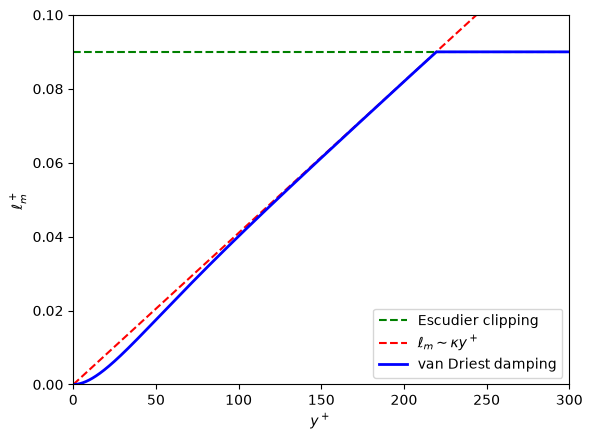

In [82]:
plt.figure()
lp1 = kappa * yp
plt.hlines(0.09,0,Retau,colors='g',linestyle='--',label='Escudier clipping')
plt.plot(yp,lp1/Retau,'r--',label=r"$\ell_m\sim \kappa y^+$")
plt.plot(yp,lp/Retau,'b',lw=2,label=r"van Driest damping")

plt.xlabel(r'$y^+$')
plt.ylabel(r'$\ell_m^+$')

plt.ylim(0,0.1)
plt.xlim(0,300)
plt.legend(loc='lower right')
plt.show()